In [1]:
import tensorflow as tf
import os
import filetype
import cv2
import random
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import glob
import numpy as np
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
import re
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_auc_score,
                             precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

/Users/george/Documents/projects/Pneumonia-image-classifier/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
data_dir = 'data'
imageTypes = ["jpg", "jpeg", "png", "bmp"]

In [3]:
'''
for data_type in os.listdir(data_dir):
    for image_class in os.listdir(data_dir): 
        for image in os.listdir(os.path.join(data_dir, image_class)):
            image_path = os.path.join(data_dir, image_class, image)
            try: 
                img = cv2.imread(image_path)
                kind = filetype.guess(image_path)
                if kind is None or kind.extension not in imageTypes:
                    print(f'Image {image_path} is of type {kind}. Should be in {imageTypes}')
                    os.remove(image_path)
            except Exception as e: 
                print('Issue with image {}'.format(image_path))
                os.remove(image_path)
'''

"\nfor data_type in os.listdir(data_dir):\n    for image_class in os.listdir(data_dir): \n        for image in os.listdir(os.path.join(data_dir, image_class)):\n            image_path = os.path.join(data_dir, image_class, image)\n            try: \n                img = cv2.imread(image_path)\n                kind = filetype.guess(image_path)\n                if kind is None or kind.extension not in imageTypes:\n                    print(f'Image {image_path} is of type {kind}. Should be in {imageTypes}')\n                    os.remove(image_path)\n            except Exception as e: \n                print('Issue with image {}'.format(image_path))\n                os.remove(image_path)\n"

In [4]:
train_normal_dir = os.path.join(data_dir, 'train/NORMAL')
train_pneu_dir = os.path.join(data_dir, 'train/PNEUMONIA')

test_normal_dir = os.path.join(data_dir, 'test/NORMAL')
test_pneu_dir = os.path.join(data_dir, 'test/PNEUMONIA')

val_normal_dir = os.path.join(data_dir, 'val/NORMAL')
val_pneu_dir = os.path.join(data_dir, 'val/PNEUMONIA')

In [5]:
train_list = []
test_list = []
val_list = []

In [6]:
def get_all_images(directory, imageTypes):
    files = []
    for ext in imageTypes:
        files.extend(glob.glob(os.path.join(directory, f'*.{ext}')))
    return files

train_normal_cases = get_all_images(train_normal_dir, imageTypes)
train_pneu_cases = get_all_images(train_pneu_dir, imageTypes)

test_normal_cases = get_all_images(test_normal_dir, imageTypes)
test_pneu_cases = get_all_images(test_pneu_dir, imageTypes)

val_normal_cases = get_all_images(val_normal_dir, imageTypes)
val_pneu_cases = get_all_images(val_pneu_dir, imageTypes)

In [7]:
train_normal_cases = [x.replace('\\', '/') for x in train_normal_cases]
train_pneu_cases = [x.replace('\\', '/') for x in train_pneu_cases]
test_normal_cases = [x.replace('\\', '/') for x in test_normal_cases]
test_pneu_cases = [x.replace('\\', '/') for x in test_pneu_cases]
val_normal_cases = [x.replace('\\', '/') for x in val_normal_cases]
val_pneu_cases = [x.replace('\\', '/') for x in val_pneu_cases]

In [8]:
for img in train_normal_cases:
    train_list.append([img, 0])
    
for img in train_pneu_cases:
    train_list.append([img, 1])
    
for img in test_normal_cases:
    test_list.append([img, 0])
    
for img in test_pneu_cases:
    test_list.append([img, 1])
    
for img in val_normal_cases:
    val_list.append([img, 0])
    
for img in val_pneu_cases:
    val_list.append([img, 1])

In [9]:
random.shuffle(train_list)

In [10]:
train_df = pd.DataFrame(train_list, columns=['image', 'label'])
test_df = pd.DataFrame(test_list, columns=['image', 'label'])
val_df = pd.DataFrame(val_list, columns=['image', 'label'])

### Validation split

The dataset's own `val/` folder has only 16 images, which is too few to guide training, so V2 originally monitored the **test set** during training and its test score was optimistic.

Instead, the 16 images are folded back into the training pool and ~15% is held out as a proper validation set. The split is:
- **stratified**, so validation keeps the same NORMAL/PNEUMONIA ratio as training
- **grouped by patient**, since many patients have several X-rays (`person123_bacteria_1.jpeg`, `person123_bacteria_2.jpeg`, ...). Otherwise near-duplicate images of the same patient would leak between train and validation.

The test set is not touched until the final evaluation.

In [11]:
def patient_id(img_path):
    # person123_bacteria_456.jpeg -> person123, IM-0115-0001.jpeg -> IM-0115, NORMAL2-IM-0123-0001.jpeg -> NORMAL2-IM-0123
    return re.match(r'(person\d+|(?:NORMAL2-)?IM-\d+)', os.path.basename(img_path)).group(1)

pool_df = pd.concat([train_df, val_df], ignore_index=True)
groups = pool_df['image'].map(patient_id)

# 7 folds -> one fold is ~14% of the data
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter.split(pool_df, pool_df['label'], groups))
train_df = pool_df.iloc[train_idx].reset_index(drop=True)
val_df = pool_df.iloc[val_idx].reset_index(drop=True)

assert not set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])
print(f'Train: {len(train_df)} images, Validation: {len(val_df)} images')
print('Validation class balance:', val_df['label'].value_counts().sort_index().to_dict())

Train: 4203 images, Validation: 688 images
Validation class balance: {0: 147, 1: 541}


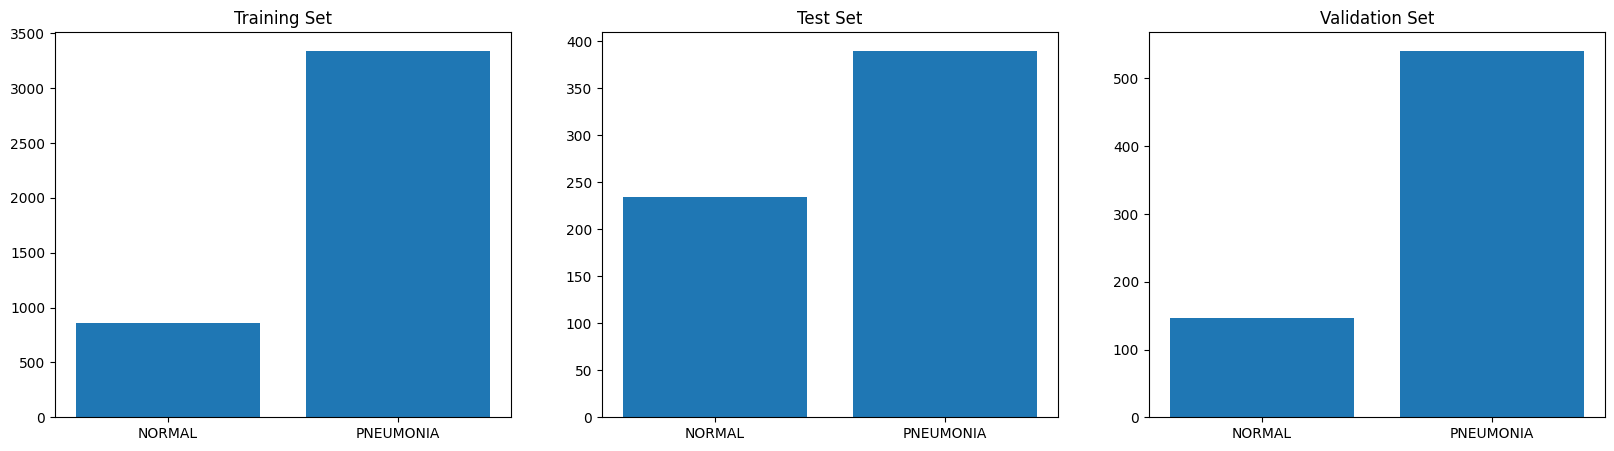

In [12]:
plt.figure(figsize=(20,5))
labels = ["NORMAL", "PNEUMONIA"]

for i, (name, df) in enumerate([("Training Set", train_df), ("Test Set", test_df), ("Validation Set", val_df)]):
    plt.subplot(1, 3, i+1)
    plt.bar(labels, df['label'].value_counts().sort_index().values)
    plt.title(name)

plt.show()

In [13]:
def process_data(img_path):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (196, 196))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img = img/255.0
    img = np.reshape(img, (196,196,1))
    return img

def compose_dataset(df):
    data = []
    labels = []
    for img_path, label in df.values:
        data.append(process_data(img_path))
        labels.append(label)
        
    return np.array(data), np.array(labels)

X_train, y_train = compose_dataset(train_df)
X_test, y_test = compose_dataset(test_df)
X_val, y_val = compose_dataset(val_df)

In [14]:
print('Train data shape: {}, Labels shape: {}'.format(X_train.shape, y_train.shape))
print('Test data shape: {}, Labels shape: {}'.format(X_test.shape, y_test.shape))
print('Validation data shape: {}, Labels shape: {}'.format(X_val.shape, y_val.shape))


Train data shape: (4203, 196, 196, 1), Labels shape: (4203,)
Test data shape: (624, 196, 196, 1), Labels shape: (624,)
Validation data shape: (688, 196, 196, 1), Labels shape: (688,)


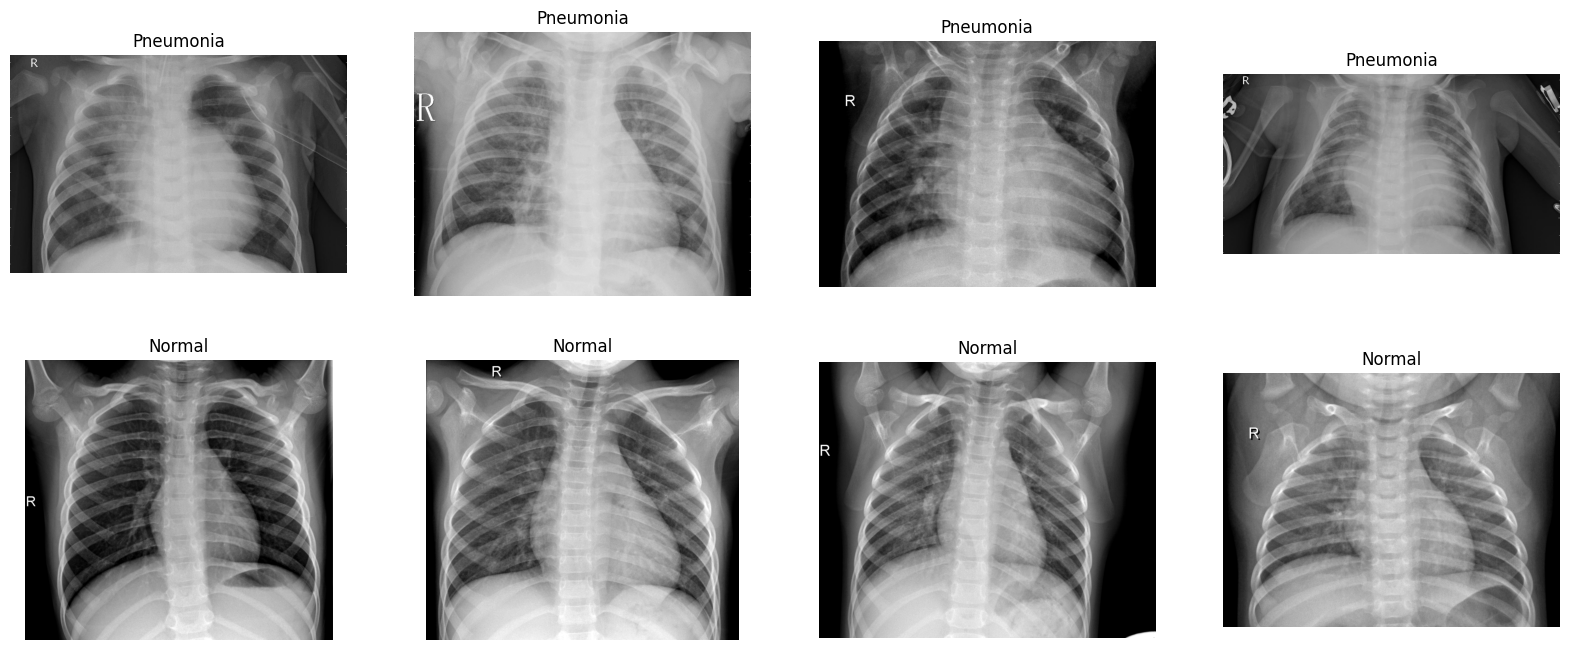

In [15]:
plt.figure(figsize=(20,8))
for i,img_path in enumerate(train_df[train_df['label'] == 1][0:4]['image']):
    plt.subplot(2,4,i+1)
    plt.axis('off')
    img = plt.imread(img_path)
    plt.imshow(img, cmap='gray')
    plt.title('Pneumonia')
    
for i,img_path in enumerate(train_df[train_df['label'] == 0][0:4]['image']):
    plt.subplot(2,4,4+i+1)
    plt.axis('off')
    img = plt.imread(img_path)
    plt.imshow(img, cmap='gray')
    plt.title('Normal')


In [16]:
y_train_cat = to_categorical(y_train, num_classes=2)
y_test_cat = to_categorical(y_test, num_classes=2)
y_val_cat = to_categorical(y_val, num_classes=2)


In [17]:
model = Sequential()

model.add(Conv2D(filters=8, kernel_size=(7,7), padding='same', activation='relu', input_shape=(196, 196, 1)))
model.add(Conv2D(filters=8, kernel_size=(7,7), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(3,3)))

model.add(Conv2D(filters=16, kernel_size=(5,5), padding='same', activation='relu'))
model.add(Conv2D(filters=16, kernel_size=(5,5), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(3,3)))

model.add(Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu'))
model.add(Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(filters=64, kernel_size=(3,3), padding='same', activation='relu'))
model.add(Conv2D(filters=64, kernel_size=(3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu'))
model.add(Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(2, activation='softmax'))

'''
optimizer = Adam(lr=0.0001, decay=1e-5)
model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])
'''

model.summary()

optimizer = Adam(learning_rate=0.0001, decay=1e-5)
model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])


callback = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
history = model.fit(X_train, y_train_cat, validation_data=(X_val, y_val_cat), batch_size=4, epochs=50, verbose=1, callbacks=[callback], class_weight={0:6.0, 1:0.5})

/Users/george/Documents/projects/Pneumonia-image-classifier/.venv/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-10-12 19:33:29.015417: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-12 19:33:29.015606: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-12 19:33:29.015609: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
I0000 00:00:1791830009.015871  953171 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791830009.016025  953171 pluggable_device_factory.cc:271] Created TensorFlow device (/job:loc

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 196, 196, 8)    │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 196, 196, 8)    │         3,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 65, 65, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 65, 65, 16)     │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 65, 65, 16)     │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 21, 21, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 21, 21, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 21, 21, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 5, 5, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 5, 5, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369,850 (1.41 MB)

 Trainable params: 369,850 (1.41 MB)

 Non-trainable params: 0 (0.00 B)

/Users/george/Documents/projects/Pneumonia-image-classifier/.venv/lib/python3.9/site-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


Epoch 1/50


2026-10-12 19:33:31.375462: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


1051/1051 ━━━━━━━━━━━━━━━━━━━━ 71s 64ms/step - accuracy: 0.4355 - loss: 0.7179 - val_accuracy: 0.8677 - val_loss: 0.2786
Epoch 2/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 67s 64ms/step - accuracy: 0.8462 - loss: 0.3031 - val_accuracy: 0.8895 - val_loss: 0.2478
Epoch 3/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 68s 64ms/step - accuracy: 0.8798 - loss: 0.2462 - val_accuracy: 0.9113 - val_loss: 0.1970
Epoch 4/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 69s 66ms/step - accuracy: 0.9101 - loss: 0.1877 - val_accuracy: 0.8997 - val_loss: 0.2219
Epoch 5/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 72s 69ms/step - accuracy: 0.9227 - loss: 0.1592 - val_accuracy: 0.9172 - val_loss: 0.1932
Epoch 6/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 71s 67ms/step - accuracy: 0.9251 - loss: 0.1546 - val_accuracy: 0.9230 - val_loss: 0.1836
Epoch 7/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 75s 71ms/step - accuracy: 0.9296 - loss: 0.1517 - val_accuracy: 0.9477 - val_loss: 0.1475
Epoch 8/50
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 75s 71ms/step - accuracy: 0.9471 - loss: 0.11

In [18]:
model.save(os.path.join('models','imageClassifier2.h5'))

## Evaluation

Missing a pneumonia case (false negative) is far worse than a false alarm, so accuracy alone is misleading. This section reports:
- a confusion matrix and per-class precision / recall / F1
- ROC-AUC and the ROC and precision-recall curves
- a **tuned decision threshold** that keeps pneumonia recall at or above a target

The threshold is chosen on the **validation set**, then applied to the test set once, so the test score stays unbiased.

In [19]:
class_names = ['NORMAL', 'PNEUMONIA']

val_probs = model.predict(X_val, verbose=0)[:, 1]
test_probs = model.predict(X_test, verbose=0)[:, 1]

def evaluate(threshold, title):
    y_pred = (test_probs >= threshold).astype(int)
    print(f'{title} (threshold = {threshold:.3f})')
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, cmap='Blues')
    plt.title(title)
    plt.show()

Default threshold (threshold = 0.500)
              precision    recall  f1-score   support

      NORMAL      0.963     0.440     0.604       234
   PNEUMONIA      0.747     0.990     0.851       390

    accuracy                          0.784       624
   macro avg      0.855     0.715     0.728       624
weighted avg      0.828     0.784     0.759       624



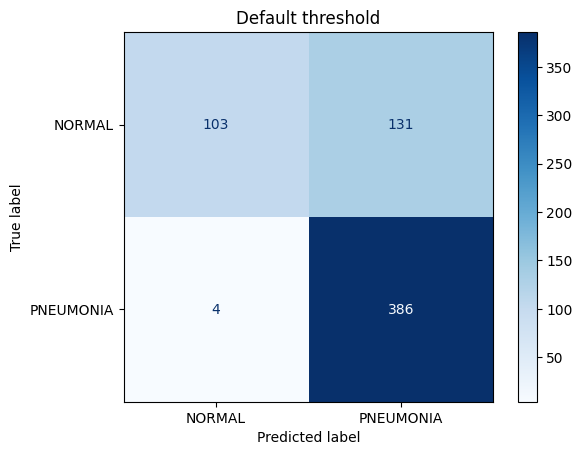

In [20]:
evaluate(0.5, 'Default threshold')

Test ROC-AUC: 0.934


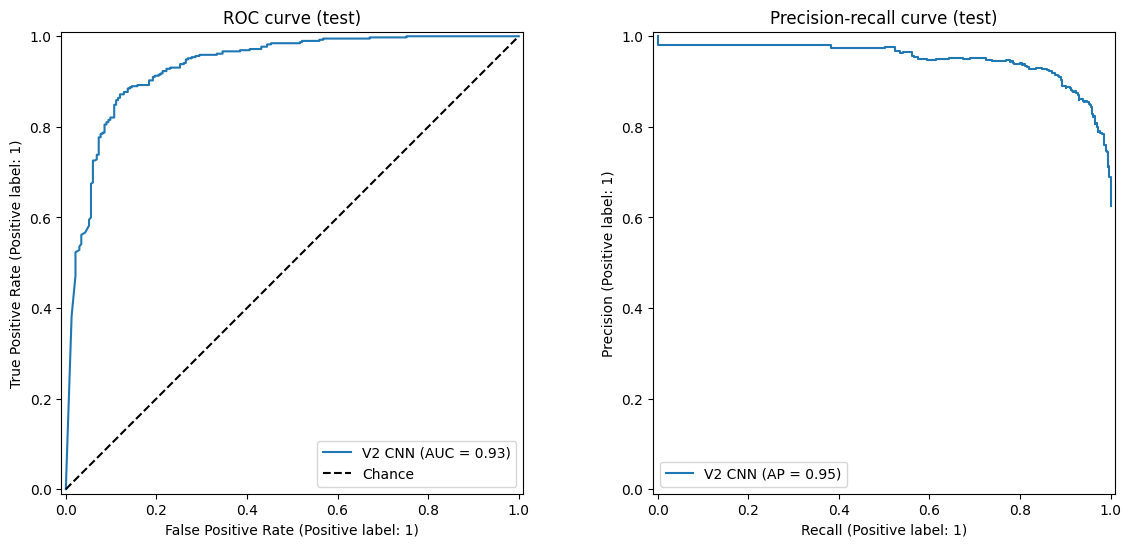

In [21]:
print(f'Test ROC-AUC: {roc_auc_score(y_test, test_probs):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
RocCurveDisplay.from_predictions(y_test, test_probs, name='V2 CNN', ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--', label='Chance')
axes[0].legend()
axes[0].set_title('ROC curve (test)')
PrecisionRecallDisplay.from_predictions(y_test, test_probs, name='V2 CNN', ax=axes[1])
axes[1].set_title('Precision-recall curve (test)')
plt.show()

### Threshold tuning

Pick the **highest** threshold whose recall on the validation set is still at least `TARGET_RECALL`. A higher threshold means fewer false alarms, so this gives the best precision that still meets the recall target.

Chosen threshold: 0.813 (validation recall 0.950, precision 0.998)
Tuned threshold (target recall 0.95) (threshold = 0.813)
              precision    recall  f1-score   support

      NORMAL      0.949     0.556     0.701       234
   PNEUMONIA      0.786     0.982     0.873       390

    accuracy                          0.822       624
   macro avg      0.868     0.769     0.787       624
weighted avg      0.847     0.822     0.809       624



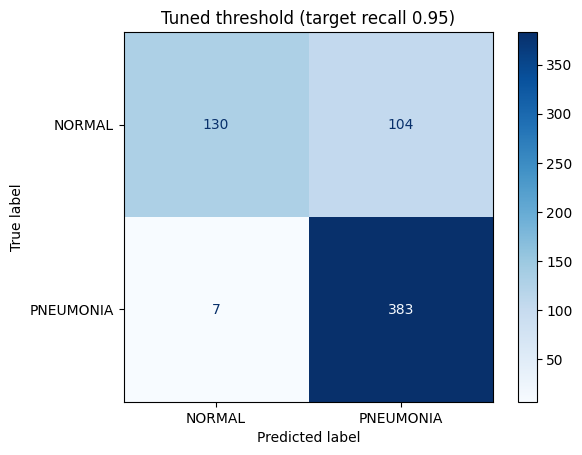

In [22]:
TARGET_RECALL = 0.95

precision, recall, thresholds = precision_recall_curve(y_val, val_probs)
# recall[i] and precision[i] belong to thresholds[i]; the final entries have no threshold
meets_target = recall[:-1] >= TARGET_RECALL
best_threshold = thresholds[meets_target].max()
i = np.where(thresholds == best_threshold)[0][0]
print(f'Chosen threshold: {best_threshold:.3f} '
      f'(validation recall {recall[i]:.3f}, precision {precision[i]:.3f})')

evaluate(best_threshold, f'Tuned threshold (target recall {TARGET_RECALL})')